In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [41]:
import os
os.listdir("data")

['prices', '.DS_Store', 'coins']

In [158]:
z = pd.read_csv("data/prices/zeph.csv")

In [160]:
n = pd.read_csv("data/prices/nova.csv")

In [161]:
a = pd.read_csv("data/prices/aurx.csv")

In [ ]:
#task 1 Prices

In [5]:
#1.1 Merge the three price files in data/prices/ into one DataFrame.
#Add a Ticker column (taken from the file name),
#convert Date to datetime and set it as the index.

In [174]:
#Add a Ticker column (taken from the file name),
d_frm = []
for name in ["ZEPH", "NOVA", "AURX"]:
    tick = pd.read_csv(f"data/prices/{name}.csv")
    tick["Ticker"] = name
    d_frm.append(tick)

In [175]:
#Merge the three price files in data/prices/ into one DataFrame.
cmb = pd.concat(d_frm)
cmb.head()

,Date,Open,High,Low,Close,Volume,Ticker
0,2024-01-01,95.05,95.69,93.04,94.11,2144777,ZEPH
1,2024-01-02,93.90,94.03,92.38,93.69,1570267,ZEPH
2,2024-01-03,93.70,100.22,92.82,96.91,2695390,ZEPH
3,2024-01-04,96.90,103.13,95.95,99.05,4045717,ZEPH
4,2024-01-05,99.25,99.98,89.71,91.81,4988231,ZEPH


In [176]:
#convert Date to datetime and set it as the index.
cmb["Date"] = pd.to_datetime(cmb["Date"])
cmb.head()
cmb["Date"].dtype

dtype('<M8[us]')

In [177]:
#set it as the index.
cmb = cmb.set_index("Date")
cmb.head()
cmb.tail()

,Open,High,Low,Close,Volume,Ticker
Date,,,,,,
2025-12-27,56349.73,56977.45,55409.71,55995.95,19928,AURX
2025-12-28,56016.30,56544.64,55720.23,55942.68,43470,AURX
2025-12-29,55901.05,56929.87,55348.96,56720.82,53065,AURX
2025-12-30,56795.23,58534.71,56100.28,56946.21,18767,AURX
2025-12-31,56949.33,57268.51,50078.70,50875.93,65698,AURX


In [ ]:
#1.2 For each coin, find the highest and the lowest price it recorded, 
#and the date on which each occurred.

In [183]:
for Ticker, i in cmb.groupby("Ticker"):
    maxP = i.loc[i["High"].idxmax()]
    minP = i.loc[i["Low"].idxmin()]
    print(f"{Ticker}")
    print(f"Highest: {maxP["High"]} on {maxP.name}")
    print(f"Lowest: {minP["Low"]} on {minP.name}")

AURX
Highest: 71741.11 on 2025-07-02 00:00:00
Lowest: 25047.4 on 2024-05-11 00:00:00
NOVA
Highest: 10402.69 on 2025-12-21 00:00:00
Lowest: 2214.24 on 2024-01-06 00:00:00
ZEPH
Highest: 255.68 on 2025-11-27 00:00:00
Lowest: 41.14 on 2024-11-26 00:00:00


In [ ]:
#1.3 Calculate the daily percentage return of Close for each coin
#(see the formula at the end) and report its mean, standard deviation, min and max.

In [180]:
# Ensure rows are sorted chronologically within each coin (if your index is Date)
cmb = cmb.sort_index()

# 1. Calculate Daily % Return per coin inside the loop
for Ticker, i in cmb.groupby("Ticker"):
    cmb.loc[i.index, "Daily % Return"] = ((i["Close"] - i["Close"].shift(1)) / i["Close"].shift(1)) * 100

# 2. Un-indent this line so it runs ONCE after the loop finishes and displays the table
cmb.groupby("Ticker")["Daily % Return"].agg(["mean", "std", "min", "max"])


,mean,std,min,max
Ticker,,,,
AURX,0.231238,5.4386,-27.527457,29.878319
NOVA,0.231238,5.4386,-27.527457,29.878319
ZEPH,0.231238,5.4386,-27.527457,29.878319


In [ ]:
#1.4 Compute the average Close for each calendar month and each coin.
#Report the highest monthly average of each coin.

In [185]:
# Group by Ticker and calendar month, then calculate the mean Close
monthly_avg = cmb.groupby(["Ticker", cmb.index.to_period("M")])["Close"].mean()
for ticker, g in monthly_avg.groupby(level="Ticker"):
    best_month = g.idxmax()[1]   # Extracts the (Ticker, Month) tuple and gets the Month
    best_val = g.max()
    print(f"{ticker}: Highest monthly average was {best_val:.2f} in {best_month}")


AURX: Highest monthly average was 63652.23 in 2025-07
NOVA: Highest monthly average was 9520.22 in 2025-12
ZEPH: Highest monthly average was 210.10 in 2025-11


In [ ]:
#1.5 Plot the Close of AURX together with its 30-day rolling mean.

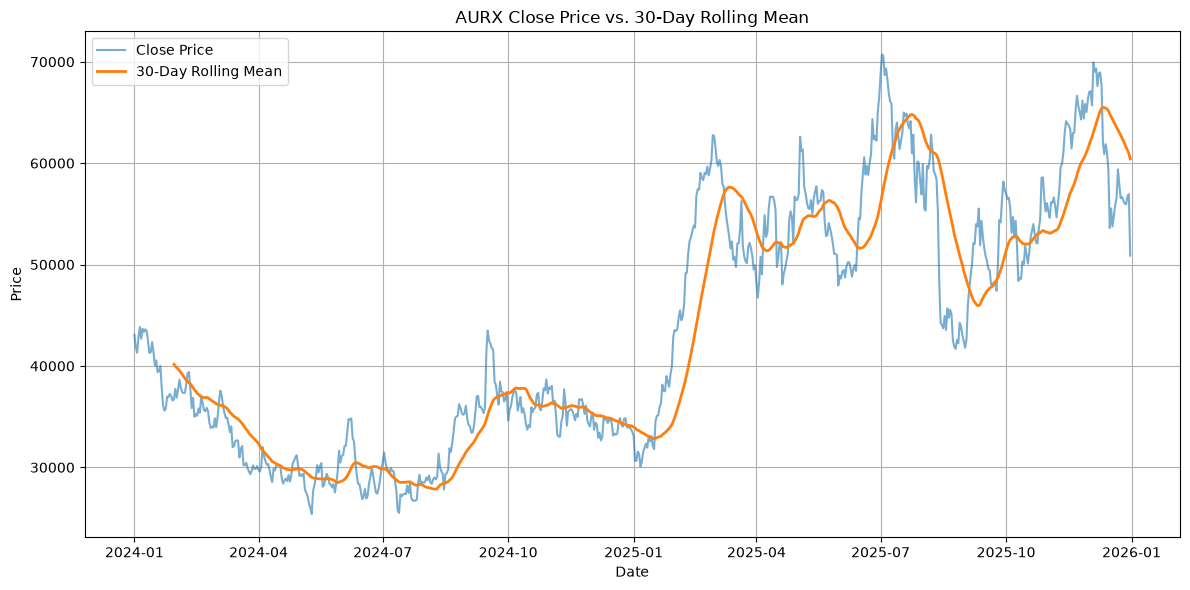

In [186]:
# 1. Filter for AURX and ensure chronological order
aurx = cmb[cmb["Ticker"] == "AURX"].sort_index()

# 2. Calculate the 30-day rolling mean of Close
rolling_30 = aurx["Close"].rolling(window=30).mean()

# 3. Plot Close and 30-day rolling mean
plt.figure(figsize=(12, 6))
plt.plot(aurx.index, aurx["Close"], label="Close Price", alpha=0.6)
plt.plot(aurx.index, rolling_30, label="30-Day Rolling Mean", linewidth=2)

# 4. Formatting
plt.title("AURX Close Price vs. 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#task 2 Coin Metadata

In [7]:
#2.1 Load the file. How many missing values does each column have?
#Convert listed to datetime and remove the coins with a missing listing date.

In [188]:
ysb = pd.read_csv("data/coins/coins_subcategory.csv")
ysb

,ticker,subcategory
0,IONI,Compute
1,OMAI,Lending
2,IONU,Scaling
3,LYRI,Lending
4,MYRI,Algorithmic
5,MYRA,Payments
6,MYRO,Payments
7,YULI,Private payments
8,SOLI,Storage
9,AURX,Payments


In [191]:
nsb = pd.read_csv("data/coins/coins_no_subcategory.csv")
nsb

,ticker,name,category,listed,founded
0,LYRE,Lyrex,Stablecoin,2014-11-15,2014-07
1,HELU,Helus,DeFi,NaN,2017 (mainnet)
2,NOVA,Nova Protocol,DeFi,2022-09-13,2022-03
3,VELO,Velora,Stablecoin,2016-07-21,2014 (mainnet)
4,LUMO,Lumon,Layer 1,2017-01-11,2017
5,ZEPE,Zepex,DeFi,NaN,2016-04
6,DYNI,Dynix,Stablecoin,2016-06-08,2014-01-19
7,VORO,Vorora,Infrastructure,2017-09-07,2016-03
8,LYRI,Lyris,DeFi,NaN,2016
9,MYRI,Myris,Stablecoin,2017-08-24,2016-10-14


In [ ]:
#2.2 Which coin has the oldest and which the youngest listing date?

In [ ]:
#2.3 Join this dataset with coins_subcategory.csv using an appropriate key and report how many coins fall into each subcategory.

In [ ]:
#task 3 NumPy

In [ ]:
#3.1 Using NumPy, generate 500 random numbers from a normal distribution (mean 0, standard deviation 1) 
#and 500 random numbers from a uniform distribution between 0 and 1.
#Print the mean and standard deviation of each sample.

In [ ]:
#3.2 Plot a histogram of each sample, side by side in one figure, with a title for each.

In [ ]:
#Bonus Fibonacci

In [ ]:
#Use a for loop to compute the first 15 Fibonacci numbers
#and store them in a list.

In [ ]:
#Using a for loop and an if condition,\
#compute the sum of the even numbers in your Fibonacci list.